In [1]:
import xgboost as xgb
from dataloaders import EnhancersDatasetClassical
import shap
import pandas as pd
import sklearn
import numpy as np
import matplotlib.pyplot as plt
import joblib

/s/chromatin/a/nobackup/Saira/miniconda3/envs/shap_clean/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model = joblib.load('svm_gird_search_new/svm_model.joblib')
model

{'model': SVC(C=10, class_weight='balanced', gamma=0.0001, probability=True,
     random_state=42),
 'params': {'C': 10, 'gamma': 0.0001, 'kernel': 'rbf'}}

In [3]:
track_matrix = "/s/chromatin/c/nobackup/Saira/BERTModel/DATA/enhancers/enh_600_2w_disc.csv"
labels_file = "/s/chromatin/c/nobackup/Saira/BERTModel/DATA/enhancers/enhancers_600_labels.txt"
win = 3
split_file = None

In [2]:
track_matrix = "/s/chromatin/c/nobackup/Saira/BERTModel/DATA/enhancers/enhances_full_500_5_chrombert_style_final.csv"
labels_file = "/s/chromatin/c/nobackup/Saira/BERTModel/DATA/enhancers/C1_2500_enhancer_dataset.txt"
win = 5
split_file = None
filter_by = None #new_hm_mask.npy"#"dna_binding_mask.npy"#histone_mask

In [3]:
dataset = EnhancersDatasetClassical(
        track_matrix_path=track_matrix,
        labels_file_path=labels_file,
        n_windows=win,
        split_file=split_file,
        filter_by=filter_by
    )
 

 
    # Use Split column from labels (Train/Test) by default
use_split_file = split_file is not None
data = dataset.get_split_sklearn_data(
        aggregation="middle",
        use_split_file=use_split_file,
    )


  Chromosome     Start       End  Split FeatureType  Label
0       Chr4  12799556  12802056   Test    Enhancer      1
1       Chr5   4472660   4475160  Train    Enhancer      1
2       Chr3   5064654   5067154  Train    Enhancer      1
3       Chr1   3611198   3613698  Train    Enhancer      1
4       Chr4   6617972   6620472  Train    Enhancer      1
NaN labels: 0

Loading track matrix from /s/chromatin/c/nobackup/Saira/BERTModel/DATA/enhancers/enhances_full_500_5_chrombert_style_final.csv...
  Loaded in 9.1s: (47584, 2690)
                        DRX066760  DRX066765  DRX066790  DRX066795  DRX066755  \
window                                                                          
Chr1:10743183-10743683          5          5          5          5          5   
Chr5:3361977-3362477            5          5          5          5          5   
Chr4:11507748-11508248          5          5          5          5          5   
Chr1:27194064-27194564          5          5          5         

In [48]:
out_dir = "final_enhancers_DNA_c1"
#out_dir = "final_enhancers_histone_c1"
out_dir = "5_embeddings_C1_dna"
#out_dir = "5_embeddings_C1_hm"
out_dir = "5_embeddings_C1_xgb_HM_2" # temp
#out_dir = "5_embeddings_C1_xgb_HM" # temp

In [10]:
svm_model_rbf = joblib.load(f"{out_dir}/svm_model_rbf.joblib")

In [11]:
svm_model_rbf

{'model': SVC(C=10, class_weight='balanced', probability=True, random_state=42)}

In [7]:
svm_model_rbf

{'model': SVC(C=10, class_weight='balanced', gamma=0.0001, probability=True,
     random_state=42),
 'params': {'C': 10, 'gamma': 0.0001, 'kernel': 'rbf'}}

In [41]:
X_train, y_train = data["train"]

In [42]:
X_test, y_test = data["test"]
X_val, y_val = data["val"]

In [43]:
X_test.shape

(3309, 947)

In [ ]:
import joblib
bst = joblib.load(f"../results/{out_dir}/xgb_model_l2.joblib")["model"]


In [4]:
#gene expression 
xgb_dir ="xgb_5emb"
bst = xgb.Booster()
bst.load_model(f'{xgb_dir}/xgb_model.ubj')


In [7]:
from baselines_gene_expression import featurize
from dataloaders import GeneExpressionDataset
import os
base_dir ="/s/chromatin/c/nobackup/Saira/BERTModel"
dataset = GeneExpressionDataset(
        cont_matrix_path=None,
        disc_matrix_path=os.path.join(base_dir, "DATA/gene expression/gene_Exp_500__5emb_disc.csv"), #gene_Exp_500_disc
        labels_file=os.path.join(base_dir, "gene expression/arabidopsis_expression_data.h5"),
        filter_by=None
    )#new_hm_mask.npy"
splits = dataset.load_splits(split_path=os.path.join(base_dir, "gene expression/"))

X_test,  Y_test, indx_to_gene_test  = featurize(dataset, splits["test"])

Original disc_matrix columns: ['DRX066760', 'DRX066765', 'DRX066790', 'DRX066795', 'DRX066755', 'DRX066785', 'DRX066761', 'DRX066766', 'DRX066791', 'DRX066796', 'DRX066756', 'DRX066786', 'DRX066762', 'DRX066767', 'DRX066792', 'DRX066797', 'DRX066757', 'DRX066787', 'DRX066763', 'DRX066768', 'DRX066793', 'DRX066798', 'DRX066758', 'DRX066788', 'DRX066815', 'DRX092564', 'DRX092566', 'DRX092570', 'DRX158892', 'DRX158888', 'DRX158884', 'DRX158880', 'DRX158916', 'DRX158893', 'DRX158889', 'DRX158914', 'DRX158885', 'DRX158881', 'DRX158894', 'DRX158890', 'DRX158886', 'DRX158882', 'DRX158912', 'DRX185860', 'DRX207473', 'DRX185863', 'DRX185866', 'DRX185857', 'DRX185872', 'DRX207475', 'DRX185875', 'DRX185878', 'DRX185869', 'DRX225520', 'DRX225525', 'DRX225526', 'DRX225505', 'DRX225506', 'DRX225504', 'DRX225467', 'DRR235286', 'DRX225483', 'DRX225491', 'DRX225495', 'DRR235292', 'DRX225487', 'DRR235289', 'DRX225485', 'DRX225493', 'DRX225464', 'DRR235283', 'DRX225481', 'DRX225489', 'DRX225468', 'DRR235

In [8]:
disc_matrix_path=os.path.join(base_dir, "DATA/gene expression/gene_Exp_500__5emb_disc.csv")
track_df = pd.read_csv(disc_matrix_path, index_col=0)



In [10]:
track_df.head()

,DRX066760,DRX066765,DRX066790,DRX066795,DRX066755,DRX066785,DRX066761,DRX066766,DRX066791,DRX066796,...,SRX9770825,SRX9770829,SRX9770833,SRX9770837,SRX9770841,SRX9770845,SRX9770849,SRX9770853,SRX9770857,SRX9770865
window,,,,,,,,,,,,,,,,,,,,,
Chr1:AT1G01010|3631:5899|w0|1,4,4,5,5,5,4,3,2,3,3,...,1,2,1,2,2,2,1,2,2,1
Chr1:AT1G01020|6788:9130|w0|-1,3,2,2,2,3,2,4,4,4,4,...,2,1,1,1,1,2,2,1,1,1
Chr1:AT1G01030|11649:13714|w0|-1,2,2,2,2,2,2,5,5,5,5,...,1,2,2,2,1,2,2,2,2,2
Chr1:AT1G01040|23121:31227|w0|1,5,5,5,5,5,5,1,1,1,2,...,1,2,2,1,2,2,2,1,1,1
Chr1:AT1G01050|31170:33171|w0|-1,3,3,3,3,3,3,2,2,2,2,...,2,1,2,1,2,1,2,1,2,1


In [11]:
index_to_col = dict(zip(range(track_df.shape[1]), track_df.columns))
feature_names = [index_to_col[i] for i in range(len(index_to_col))]

In [12]:
X_test_df = pd.DataFrame(
    X_test,
    columns=feature_names,
)

In [13]:
explainer = shap.TreeExplainer(bst)
shap_values = explainer.shap_values(X_test_df)

: 

In [9]:
# svm linear
svm_model_linear = joblib.load(f"../results/{out_dir}/svm_model_linear.joblib")["model"]
svm_model_rbf = joblib.load(f"../results/{out_dir}/svm_model_rbf.joblib")["model"]

In [51]:
Y_pred = bst.predict(X_test, output_margin=True)


In [9]:
Y_pred = svm_model_linear.decision_function(X_test)

In [52]:
#aupr calculator
aupr = sklearn.metrics.average_precision_score(y_test, Y_pred)
print("AUPR: ", aupr)

AUPR:  0.966164052386263


In [53]:
pos_index = [i for i, x in enumerate(y_test) if x == 1]

In [4]:
#metadata = pd.read_csv("/s/chromatin/c/nobackup/Saira/BERTModel/DATA/AT_CSP_Metadata 1.csv", index_col=0)
metadata = pd.read_csv("/s/chromatin/c/nobackup/Saira/BERTModel/merged_metadata_AT_OCR.csv", index_col=0)

In [4]:
missing_srr = np.loadtxt("missing_files.txt", dtype=str)

In [7]:
missing_metadata = metadata[metadata["Sample accession number"].isin(missing_srr)]

In [46]:
metadata

,BioProject ID,Protocol,Factor_x,Experiment Name,Replicate_x,Sample accession,Sample name,Sample group,Reference,Sample accession number,...,Temperature,Mutant,Mutant_specific,Cultivar,Strain,Factor_y,Factor_type,Factor_type_specific,Unnamed: 19,Type_Strain
Species,,,,,,,,,,,,,,,,,,,,,
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_ibm1,Rep1,DRX066760,H3K4me1,histone related,28100676,DRX066760,...,NaN,Mutant,ibm1,NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_ibm1_ldl2,Rep1,DRX066765,H3K4me1,histone related,28100676,DRX066765,...,NaN,Mutant,"ibm1, ldl2",NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_ldl2,Rep1,DRX066790,H3K4me1,histone related,28100676,DRX066790,...,NaN,Mutant,ldl2,NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_suvh456,Rep1,DRX066795,H3K4me1,histone related,28100676,DRX066795,...,NaN,Mutant,"suvh4, suvh5, suvh6",NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_WT_12,Rep1,DRX066755,H3K4me1,histone related,28100676,DRX066755,...,NaN,WT,WT,NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Arabidopsis thaliana,SRP300093,ATAC-seq,Open chromatin,SRX9770845,Rep1,SRX9770845,NaN,OCR,NaN,SRX9770845,...,22.0,Mutant,No,NaN,NaN,OCR,OCR,OCR,NaN,Non_Col-0
Arabidopsis thaliana,SRP300093,ATAC-seq,Open chromatin,SRX9770849,Rep1,SRX9770849,NaN,OCR,NaN,SRX9770849,...,22.0,Mutant,Nw,NaN,NaN,OCR,OCR,OCR,NaN,Non_Col-0
Arabidopsis thaliana,SRP300093,ATAC-seq,Open chromatin,SRX9770853,Rep1,SRX9770853,NaN,OCR,NaN,SRX9770853,...,22.0,Mutant,Og,NaN,NaN,OCR,OCR,OCR,NaN,Non_Col-0


In [11]:
metadata.head(5)

,Sample accession number,Replicate,Tissue,Tissue_specific,Age (days),Light exposure,Growth media,Growth media specific,Treatment,Treatment_specific,Temperature,Mutant_specific,Mutant,Strain,Cultivar,Factor,Factor_type,Factor_type_specific,Experiment Name,bed_file
BioProject ID,,,,,,,,,,,,,,,,,,,,
DRP006224,DRR235283,Rep1,Whole plant,Whole plant,14.0,Long day,MS,MS,No treatment,No treatment,NaN,WT,WT,Col-0,Col,H3K4me1,histone related,histone methylation,H3K4me1_WT_A,/s/chromatin/d/nobackup/ahmed/DeepPlantV2/raw_...
DRP006224,DRR235284,Rep1,Whole plant,Whole plant,14.0,Long day,MS,MS,No treatment,No treatment,NaN,WT,WT,Col-0,Col,H3K4me2,histone related,histone methylation,H3K4me2_WT_A,/s/chromatin/d/nobackup/ahmed/DeepPlantV2/raw_...
DRP006224,DRR235286,Rep1,Whole plant,Whole plant,14.0,Long day,MS,MS,No treatment,No treatment,NaN,fld,Mutant,Col-0,Col,H3K4me1,histone related,histone methylation,H3K4me1_fld_A,/s/chromatin/d/nobackup/ahmed/DeepPlantV2/raw_...
DRP006224,DRR235287,Rep1,Whole plant,Whole plant,14.0,Long day,MS,MS,No treatment,No treatment,NaN,fld-4,Mutant,Col-0,Col,H3K4me2,histone related,histone methylation,H3K4me2_fld_A,/s/chromatin/d/nobackup/ahmed/DeepPlantV2/raw_...
DRP006224,DRR235289,Rep1,Whole plant,Whole plant,14.0,Long day,MS,MS,No treatment,No treatment,NaN,sdg26,Mutant,Col-0,Col,H3K4me1,histone related,histone methylation,H3K4me1_sdg26_A,/s/chromatin/d/nobackup/ahmed/DeepPlantV2/raw_...


In [ ]:
#H3K9ac-Light-(wp-WT)

In [5]:
track_matrix_df = pd.read_csv(track_matrix, index_col=0)
if 'actual' in track_matrix_df.columns:
    track_matrix_df = track_matrix_df.drop(columns=['actual'])
all_columns = track_matrix_df.columns
if filter_by is not None:
    filter_columns =  np.load(filter_by).ravel()
    print("loaded mask for filtering features ", filter_columns.sum(), filter_columns.shape)
    track_matrix_df = track_matrix_df.loc[:, filter_columns.astype(bool)]
print("track_matrix_df shape: ", track_matrix_df.shape)
index_to_col = dict(zip(range(track_matrix_df.shape[1]), track_matrix_df.columns))

track_matrix_df shape:  (47584, 2689)


In [55]:
all_feats = []
for c in all_columns:
    if "." in c:
        print(c)
        c = c.split(".")[0]
    all_feats.append(c)

ERX3444754.rpgc
ERX3444763.rpgc
ERX3444764.rpgc
ERX3444797.rpgc
ERX3444803.rpgc


In [56]:
feature_names = [index_to_col[i] for i in range(len(index_to_col))]

In [58]:
X_test_df = pd.DataFrame(
    X_test,
    columns=feature_names,
)

In [41]:
X_test_df_pos = X_test_df.iloc[pos_index]

In [51]:
X_test_df

,DRX066760,DRX066765,DRX066790,DRX066795,DRX066755,DRX066785,DRX066761,DRX066766,DRX066791,DRX066796,...,SRX9514928,SRX9608037,SRX9608044,SRX9608039,SRX9608046,SRX9608042,SRX9608048,SRX9615654,SRX9615656,SRX9615658
0,2.0,1.0,2.0,2.0,2.0,2.0,4.0,4.0,4.0,4.0,...,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
1,2.0,2.0,2.0,2.0,2.0,2.0,5.0,5.0,5.0,5.0,...,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
2,2.0,1.0,2.0,1.0,1.0,2.0,5.0,5.0,5.0,5.0,...,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
3,2.0,2.0,2.0,2.0,2.0,2.0,5.0,5.0,5.0,5.0,...,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
4,2.0,1.0,2.0,2.0,2.0,2.0,5.0,5.0,5.0,5.0,...,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3304,2.0,2.0,2.0,2.0,2.0,2.0,4.0,4.0,4.0,4.0,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
3305,2.0,1.0,2.0,2.0,2.0,2.0,5.0,5.0,5.0,5.0,...,4.0,5.0,5.0,5.0,5.0,5.0,5.0,3.0,4.0,4.0
3306,5.0,5.0,5.0,5.0,5.0,5.0,1.0,1.0,1.0,1.0,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0
3307,2.0,2.0,2.0,2.0,2.0,2.0,4.0,4.0,4.0,4.0,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0


In [8]:
len(feature_names)

2689

In [16]:
background = shap.sample(X_train, 100, random_state=42)


In [66]:
background.shape

(1, 1509)

In [ ]:

explainer = shap.KernelExplainer(
    svm_model_linear.decision_function,
    background
)
shap_values = explainer.shap_values(X_test_df)

  0%|          | 0/3309 [00:00<?, ?it/s]

In [ ]:

explainer = shap.KernelExplainer(
    svm_model_rbf.decision_function,
    background
)
shap_values = explainer.shap_values(X_test_df)

  0%|          | 0/3309 [00:00<?, ?it/s]

In [59]:
explainer = shap.TreeExplainer(bst)

shap_values = explainer.shap_values(X_test_df)

In [60]:
shap_values

array([[-5.71552385e-03,  1.23725695e-05,  2.89774558e-04, ...,
         4.81601479e-03,  6.04283344e-03,  3.75151597e-02],
       [-3.57420952e-03, -8.56918905e-06,  2.89774558e-04, ...,
         3.07619758e-03,  6.04604138e-03,  1.27721140e-02],
       [-8.31212907e-04,  1.23725695e-05,  1.46032689e-04, ...,
         2.27644295e-03,  3.25568542e-02,  4.18127254e-02],
       ...,
       [-5.11766830e-03, -1.75018533e-04, -2.26812270e-02, ...,
        -2.04868615e-02, -6.14470392e-02, -9.96410996e-02],
       [-3.19179008e-03, -3.31932039e-04,  1.39627940e-04, ...,
        -9.38839372e-03, -7.03276545e-02, -6.65144026e-02],
       [-6.89850003e-03, -1.75018533e-04, -2.77611203e-02, ...,
        -1.36903068e-02, -7.25623146e-02, -1.11965537e-01]],
      shape=(3309, 947), dtype=float32)

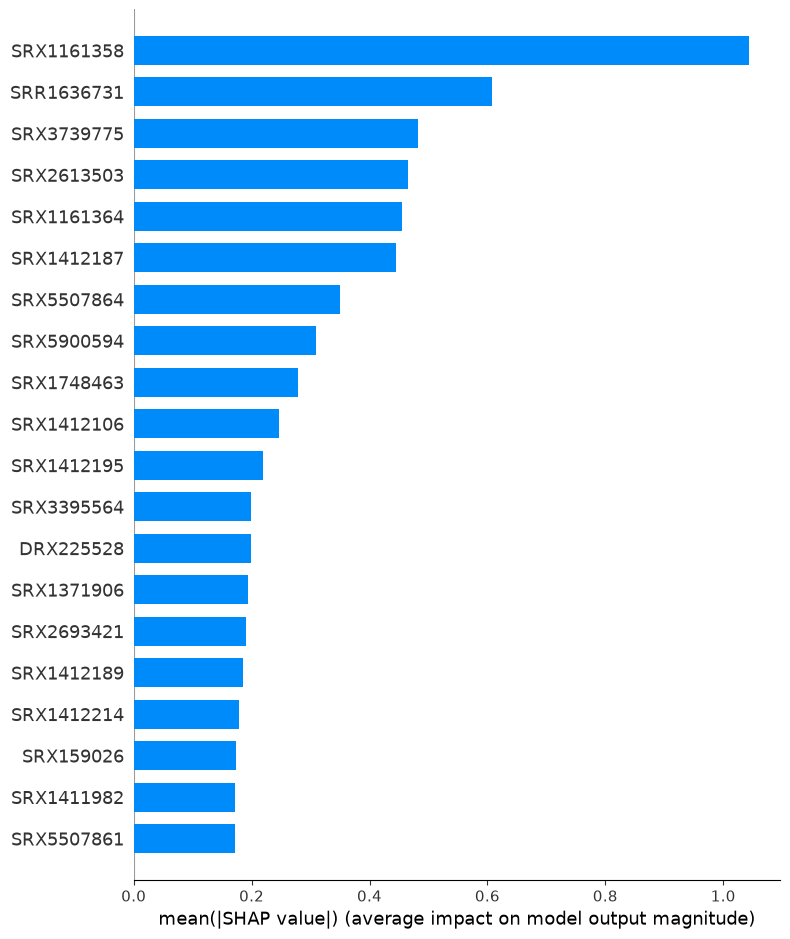

In [21]:
%matplotlib inline
shap.summary_plot(shap_values, X_test_df, feature_names=feature_names, plot_type="bar", max_display=20)

In [20]:
# bees
shap.summary_plot(shap_values, X_test_df, feature_names=feature_names, max_display=20)

In [172]:
pos_shap_values = shap_values[pos_index]

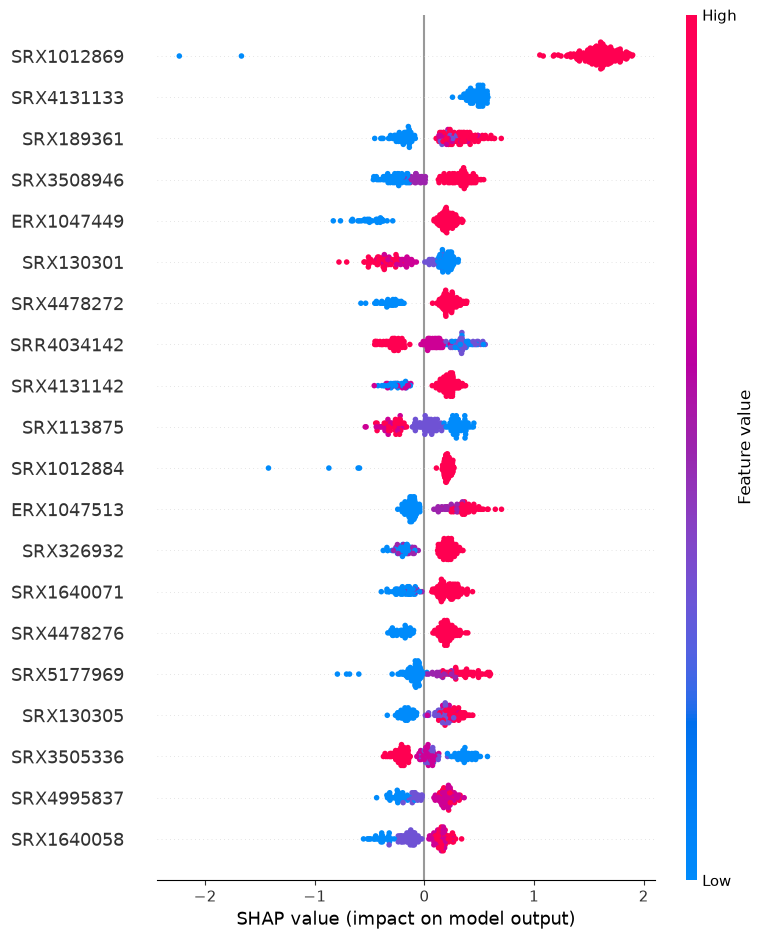

In [173]:
shap.summary_plot(pos_shap_values, X_test_df.iloc[pos_index], feature_names=feature_names, max_display=20)

In [56]:
#neg shap values
neg_index = [i for i, x in enumerate(y_test) if x == 0]
neg_shap_values = shap_values[neg_index]
shap.summary_plot(neg_shap_values, X_test_df.iloc[neg_index], feature_names=feature_names, max_display=20)

In [34]:
neg_index = [i for i, x in enumerate(y_test) if x == 0]

In [6]:
metadata.head(5)

,BioProject ID,Protocol,Factor_x,Experiment Name,Replicate_x,Sample accession,Sample name,Sample group,Reference,Sample accession number,...,Temperature,Mutant,Mutant_specific,Cultivar,Strain,Factor_y,Factor_type,Factor_type_specific,Unnamed: 19,Type_Strain
Species,,,,,,,,,,,,,,,,,,,,,
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_ibm1,Rep1,DRX066760,H3K4me1,histone related,28100676,DRX066760,...,NaN,Mutant,ibm1,NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_ibm1_ldl2,Rep1,DRX066765,H3K4me1,histone related,28100676,DRX066765,...,NaN,Mutant,"ibm1, ldl2",NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_ldl2,Rep1,DRX066790,H3K4me1,histone related,28100676,DRX066790,...,NaN,Mutant,ldl2,NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_suvh456,Rep1,DRX066795,H3K4me1,histone related,28100676,DRX066795,...,NaN,Mutant,"suvh4, suvh5, suvh6",NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0
Arabidopsis thaliana,DRP003416,ChIP-seq,H3K4me1,H3K4me1_WT_12,Rep1,DRX066755,H3K4me1,histone related,28100676,DRX066755,...,NaN,WT,WT,NaN,Col,H3K4me1,histone related,histone methylation,NaN,Col-0


In [7]:
metadata["Factor_type"].value_counts() 

Factor_type
DNA-binding protein    1547
histone related        1081
OCR                     159
histone                  82
Other                    15
DNA methylation           5
Name: count, dtype: int64

In [8]:
columns_in_data = track_df.columns
len(columns_in_data)

NameError: name 'track_df' is not defined

In [3]:
acc_to_factor = dict(zip(metadata["Sample accession number"], metadata["Factor_y"]))
acc_to_type = dict(zip(metadata["Sample accession number"], metadata["Factor_type"]))

In [9]:
feature_names_normalized = []
for f in feature_names:
    if ".rpgc" in f:
        acc = f.split(".")[0]
        feature_names_normalized.append(acc)
    else:
        feature_names_normalized.append(f)

NameError: name 'feature_names' is not defined

In [60]:
metadata[metadata["Sample accession number"].isin(feature_names_normalized)]["Factor_type"].value_counts()

Factor_type
histone related    995
Name: count, dtype: int64

In [61]:
filtered = metadata[metadata["Sample accession number"].isin(feature_names_normalized)]

In [13]:
for value_type in filtered["Factor_type"].value_counts().index:
    srrs = filtered[filtered["Factor_type"] == value_type]["Sample accession number"].values
    print(value_type, len(srrs), len(set(srrs)))

DNA-binding protein 1511 1504
histone related 995 947
OCR 159 159
histone 71 67
Other 7 7
DNA methylation 5 5


In [40]:
all_acc = set(filtered["Sample accession number"].values)

In [41]:
filtered.shape, len(all_acc), len(set(feature_names))

((2748, 29), 2689, 2689)

In [15]:
dna_binding_acc = filtered[filtered["Factor_type"] == "DNA-binding protein"]["Sample accession number"].values

In [16]:
len(dna_binding_acc), len(set(dna_binding_acc)), len(set(feature_names_normalized)), len(set(feature_names_normalized).intersection(set(dna_binding_acc)))

(1511, 1504, 2689, 1504)

In [27]:
hm_acc = filtered[filtered["Factor_type"] == "histone related"]["Sample accession number"].values

In [45]:
#load npy
dna_mask = np.load("dna_binding_mask.npy")
dna_mask.sum()

np.float64(1509.0)

In [22]:
dna_mask.shape

(1, 2689)

In [14]:
new_dna_mask = np.zeros((1 , 2689))

In [28]:
new_hm_mask = np.zeros((1 , 2689))

In [17]:
dna_binding_acc = set(dna_binding_acc)

In [29]:
print(len(hm_acc))
hm_acc = set(hm_acc)
print(len(hm_acc))


995
947


In [18]:
for i, f in enumerate(feature_names_normalized):
    # if f not in acc_to_type:
    #     print(i)
    #     continue
    if f in dna_binding_acc:
        new_dna_mask[0][i] = 1

In [21]:
np.save("new_dna_mask.npy", new_dna_mask)

In [30]:
for i, f in enumerate(feature_names_normalized):
    if f in hm_acc:
        new_hm_mask[0][i] = 1

In [32]:
new_dna_mask.shape, new_hm_mask.sum()

((1, 2689), np.float64(947.0))

In [33]:
np.save("new_hm_mask.npy", new_hm_mask)

In [10]:
### chrombert ranks
chrombert_df = pd.read_csv(f"/s/chromatin/c/nobackup/Saira/BERTModel/NOBERT/results/chrombert_finetune/finetune_models_w1_2500bp_5emb_clustered_mtx_c1/results/results/factor_importance_rank.csv")
chrombert_df["factor name"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in chrombert_df["factors"]]
chrombert_df["factor type"] = [acc_to_type[feature.split(".")[0]] if feature.split(".")[0] in acc_to_type else "unknown" for feature in chrombert_df["factors"]]

In [11]:
chrombert_dna_df = chrombert_df[chrombert_df["factor type"] == "DNA-binding protein"]
chrombert_histone_df = chrombert_df[chrombert_df["factor type"] == "histone related"]



In [12]:
chrombert_dna_df.head(15)

,factors,similarity,rank,embedding_shift,factor name,factor type
264,SRX1161364,0.194858,265,0.805142,MORC1,DNA-binding protein
267,SRX5507864,0.196590,268,0.803410,GRF3,DNA-binding protein
274,SRX1161361,0.203851,275,0.796149,MORC1,DNA-binding protein
288,SRX1161368,0.221119,289,0.778881,MORC1,DNA-binding protein
290,SRR1636731,0.225936,291,0.774064,SDG8,DNA-binding protein
293,SRX1161358,0.228306,294,0.771694,MORC1,DNA-binding protein
315,SRX3119798,0.252900,316,0.747100,ENAP1,DNA-binding protein
335,SRX4705000,0.279200,336,0.720800,UBQ10,DNA-binding protein
345,SRX7573320,0.298156,346,0.701844,MED12,DNA-binding protein
365,SRX159109,0.325576,366,0.674424,NRPE1,DNA-binding protein


In [13]:
chrombert_histone_df.head(15)

,factors,similarity,rank,embedding_shift,factor name,factor type
0,SRX5735626,-0.064786,1,1.064786,H3K4me3,histone related
1,SRX5177413,-0.054729,2,1.054728,H3K4me3,histone related
2,SRX5735624,-0.048878,3,1.048878,H3K4me3,histone related
3,SRX5177419,-0.046739,4,1.046739,H3K4me3,histone related
4,SRX7573325,-0.042352,5,1.042352,H3K4me3,histone related
5,DRX066787,-0.040876,6,1.040876,H3K4me3,histone related
6,SRX6057524,-0.035128,7,1.035128,H3ac,histone related
7,DRX066792,-0.027948,8,1.027948,H3K4me3,histone related
8,SRX5177415,-0.026132,9,1.026131,H3K4me3,histone related
9,SRX7573293,-0.025876,10,1.025876,H3K4me3,histone related


In [14]:
chrombert_dna_df.to_csv(f"../results/chrombert_finetune/finetune_models_w1_2500bp_5emb_clustered_mtx_c1/chrombert_dna_factor_importance_rank.csv", index=False)
chrombert_histone_df.to_csv(f"../results/chrombert_finetune/finetune_models_w1_2500bp_5emb_clustered_mtx_c1/chrombert_histone_factor_importance_rank.csv", index=False)

In [5]:
## chrombert IG ranks
ig_chrombert_df = pd.read_csv(f"/s/chromatin/c/nobackup/Saira/BERTModel/NOBERT/results/chrombert_finetune/finetune_models_w1_2500bp_5emb_clustered_mtx_c1/results/results/true_positive_feature_attribution.csv")
ig_chrombert_df["factor type"] = [acc_to_type[feature.split(".")[0]] if feature.split(".")[0] in acc_to_type else "unknown" for feature in ig_chrombert_df["cistrome"]]
ig_chrombert_df["factor name"] = [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in ig_chrombert_df["cistrome"]
]
ig_chrombert_dna_df = ig_chrombert_df[ig_chrombert_df["factor type"] == "DNA-binding protein"]
ig_chrombert_histone_df = ig_chrombert_df[ig_chrombert_df["factor type"] == "histone related"]

In [6]:
ig_chrombert_histone_df.head(5)

,cistrome,mean_attribution,mean_abs_attribution,rank,factor type,factor name
5,SRX4478276,0.018039,0.018039,6,histone related,H3K9me2
9,SRX8526502,-0.014616,0.014616,10,histone related,H2AZ
21,SRX1640080,0.011018,0.011018,22,histone related,H2B
24,SRX9514924,0.010487,0.010487,25,histone related,H3K9ac
25,ERX1047513,0.008619,0.010407,26,histone related,H3S10p


In [7]:
ig_chrombert_dna_df.head(10)

,cistrome,mean_attribution,mean_abs_attribution,rank,factor type,factor name
1,SRX1412187,0.024862,0.024862,2,DNA-binding protein,GATA11
3,DRX225528,-0.022357,0.022357,4,DNA-binding protein,TOP1A
4,SRX1412185,0.019920,0.019920,5,DNA-binding protein,GATA1
6,SRX1412522,0.016642,0.016731,7,DNA-binding protein,ANAC017
7,SRX5488559,0.015576,0.015576,8,DNA-binding protein,AGL16
10,SRX8718706,0.014296,0.014423,11,DNA-binding protein,RDM15
11,SRX488722,-0.014418,0.014418,12,DNA-binding protein,DEK3
13,SRX1161361,0.013234,0.013234,14,DNA-binding protein,MORC1
14,SRX6875218,0.011546,0.012963,15,DNA-binding protein,TCX5
15,SRX5213628,-0.002859,0.012526,16,DNA-binding protein,FLAG


In [8]:
ig_chrombert_dna_df.to_csv(f"../results/chrombert_finetune/finetune_models_w1_2500bp_5emb_clustered_mtx_c1/ig_chrombert_dna_factor_importance_rank_2.csv", index=False)
ig_chrombert_histone_df.to_csv(f"../results/chrombert_finetune/finetune_models_w1_2500bp_5emb_clustered_mtx_c1/ig_chrombert_histone_factor_importance_rank_2.csv", index=False)

In [75]:
# svm rbf shap
rbf_svm_shap_df = pd.read_csv(f"../results/{out_dir}/rbf_shap_values.csv")
rbf_svm_shap_df.shape

(3309, 1504)

In [71]:
# svm rbf shap
linear_svm_shap_df = pd.read_csv(f"../results/{out_dir}/linear_shap_values.csv")
linear_svm_shap_df.shape

(3309, 947)

In [79]:
linear_svm_shap_df = pd.read_csv(f"../results/{out_dir}/linear_shap_values.csv")
linear_svm_shap_df.shape

(3309, 1504)

In [25]:
linear_svm_shap_df.head(10)

,DRX066815,DRX092564,DRX092566,DRX092570,DRX158912,DRX185860,DRX207473,DRX185863,DRX185866,DRX185857,...,SRX8840847,SRX8874569,SRX9057646,SRX9288313,SRX9288315,SRX9352674,SRX9352673,SRX9822239,SRX10067412,SRX10566680
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [76]:
sv = rbf_svm_shap_df.values
signed_pos = sv[pos_index].mean(axis=0)
signed_neg = sv[neg_index].mean(axis=0)
rank = (pd.DataFrame({
            'feature': rbf_svm_shap_df.columns,
            'signed_pos': signed_pos,
            'signed_neg': signed_neg,
            'separation': signed_pos - signed_neg,
            'abs_infl': np.abs(sv).mean(0),
        })
        .sort_values('signed_pos', ascending=False))
rank["factor name"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in rank["feature"]]
rank["factor type"] = [acc_to_type[feature.split(".")[0]] if feature.split(".")[0] in acc_to_type else "unknown" for feature in rank["feature"]]

In [81]:
rank.head(10)

,feature,signed_pos,signed_neg,separation,abs_infl,factor name,factor type
1063,SRX1519409,0.048086,0.000555,0.047530,0.003314,PolII,DNA-binding protein
1021,SRR1636731,0.040540,0.000316,0.040225,0.002672,SDG8,DNA-binding protein
1397,SRX5507864,0.035419,0.000281,0.035139,0.002320,GRF3,DNA-binding protein
73,SRX159111,0.027171,0.000276,0.026895,0.001836,NRPE1,DNA-binding protein
1468,SRX7573314,0.019017,0.000135,0.018882,0.001231,MED12,DNA-binding protein
1242,SRX3255811,0.018208,0.000184,0.018024,0.001230,SYD,DNA-binding protein
20,DRX225508,0.016278,0.000119,0.016160,0.001056,PolII,DNA-binding protein
1348,SRX5177269,0.015879,0.000102,0.015778,0.001017,S2LB,DNA-binding protein
1033,SRX1161358,0.015016,0.000274,0.014743,0.001129,MORC1,DNA-binding protein
1354,SRX5213637,0.014390,0.000038,0.014353,0.000870,AGO4,DNA-binding protein


In [78]:
rank.to_csv(f"../results/{out_dir}/rbf_svm_shap_values_rank.csv", index=False)

In [80]:
sv = linear_svm_shap_df.values
signed_pos = sv[pos_index].mean(axis=0)
signed_neg = sv[neg_index].mean(axis=0)
rank = (pd.DataFrame({
            'feature': linear_svm_shap_df.columns,
            'signed_pos': signed_pos,
            'signed_neg': signed_neg,
            'separation': signed_pos - signed_neg,
            'abs_infl': np.abs(sv).mean(0),
        })
        .sort_values('signed_pos', ascending=False))
rank["factor name"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in rank["feature"]]
rank["factor type"] = [acc_to_type[feature.split(".")[0]] if feature.split(".")[0] in acc_to_type else "unknown" for feature in rank["feature"]]

In [82]:
rank.to_csv(f"../results/{out_dir}/linear_svm_shap_values_rank.csv", index=False)

In [61]:
sv = shap_values
signed_pos = sv[pos_index].mean(0)
signed_neg = sv[neg_index].mean(0)

import pandas as pd
rank = (pd.DataFrame({
            'feature': feature_names,
            'signed_pos': signed_pos,
            'signed_neg': signed_neg,
            'separation': signed_pos - signed_neg,
            'abs_infl': np.abs(sv).mean(0),
        })
        .sort_values('signed_pos', ascending=False))
rank["factor name"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in rank["feature"]]
#rank["label"] = [acc_to_label[feature.split(".")[0]] if feature.split(".")[0] in acc_to_label else feature.split(".")[0] for feature in rank["feature"]]

In [62]:
rank.head(20)

,feature,signed_pos,signed_neg,separation,abs_infl,factor name
629,SRX4131133,3.142170,-1.196691,4.338861,1.552614,H3K4me3
562,SRX3503871,0.046922,-0.006635,0.053557,0.014129,H3K9me2
107,ERX1047513,0.040991,-0.028509,0.069499,0.047748,H3S10p
585,SRX4478272,0.036385,-0.088260,0.124644,0.097765,H3K9me2
87,ERX1047473,0.032682,-0.015632,0.048314,0.019086,H3K27ac
146,ERX3510579,0.025553,-0.060044,0.085597,0.068903,H3K9ac|H3K14ac
317,SRX1331880,0.019818,-0.105405,0.125223,0.104862,H3K4me3
459,SRX2311141,0.016085,-0.105999,0.122084,0.102499,H3K9ac
941,SRX9608046,0.014652,-0.126228,0.140880,0.122278,H3K4me3
946,SRX9615658,0.014587,-0.088627,0.103214,0.088215,H3ac


In [63]:
rank.to_csv(f"../results/{out_dir}/tree_shap_feature_importance.csv", index=False)

In [51]:
booster = bst.get_booster()

tree_weights= booster.get_score(importance_type="weight")
tree_scores = {}
for i in range(len(X_test_df.columns)):
    tree_scores[X_test_df.columns[i]] = tree_weights.get(f"f{i}", 0)
# feature importance plot
feats_df_tree = pd.DataFrame({
    "feature": X_test_df.columns,
    "importance": tree_scores.values(),
}).sort_values("importance", ascending=False)
feats_df_tree["factor type"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in feats_df_tree["feature"]]


In [52]:
tree_gain= booster.get_score(importance_type="gain")
tree_scores = {}
for i in range(len(X_test_df.columns)):
    tree_scores[X_test_df.columns[i]] = tree_gain.get(f"f{i}", 0)
# feature importance plot
gain_df_tree = pd.DataFrame({
    "feature": X_test_df.columns,
    "importance": tree_scores.values(),
}).sort_values("importance", ascending=False)
gain_df_tree["factor type"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in gain_df_tree["feature"]]


In [53]:

gain_df_tree.to_csv(f"../results/{out_dir}/tree_gain_feature_importance.csv", index=False)

In [54]:
feats_df_tree.to_csv(f"../results/{out_dir}/tree_weight_feature_importance.csv", index=False)

In [24]:
deepplant_res = []
with open("../results/TF_targets_deep_plant.txt", "r") as f:
    for line in f:
        deepplant_res.append(line.strip())
deepplant_factors = [x.split("-")[0] for x in deepplant_res]

In [24]:
deepplant_res = []
with open("../results/HM _targets_deepplant.txt", "r") as f:
    for line in f:
        deepplant_res.append(line.strip())
deepplant_factors = [x.split("-")[0] for x in deepplant_res]

In [45]:
# match top k
k = 30
topk_deepplant = set(deepplant_factors[:k])
topk_xgb = set(rank["factor type"][:k])
print(len(topk_deepplant), len(topk_xgb))
overlap = topk_deepplant.intersection(topk_xgb)
len(overlap)

13 17


8

In [51]:
# overlap
overlap

{'FLAG', 'GATA11', 'GRF3', 'MED12', 'PolII', 'SDG8'}

In [212]:
rank.sort_values('signed_pos', ascending=False).head(20)


,feature,signed_pos,signed_neg,separation,abs_infl,factor type,label
310,SRX1012869,1.560090,-0.709469,2.269559,0.891763,H3K4me3,H3K4me3-No treatment-Leaf_WT
683,SRX4131133,0.474622,-0.511351,0.985973,0.558068,H3K4me3,H3K4me3-No treatment-Whole plant_WT
309,SRX1012884,0.190178,-0.365129,0.555307,0.372714,H3K4me3,H3K4me3-Drought-Leaf_WT
840,SRX5184287,0.184875,-0.062682,0.247558,0.143795,H3,H3-No treatment-Whole plant_hda6
366,SRX1553727,0.149480,-0.002458,0.151939,0.021783,H3K14ac,H3K14ac-Ethylene-Whole plant_WT
1008,SRX9608046,0.146693,-0.222412,0.369104,0.234240,H3K4me3,H3K4me3-No treatment-wp_WT
728,SRX4404637,0.139315,-0.066079,0.205394,0.080273,H3K4me3,H3K4me3-No treatment-Leaf_WT
207,SRX189361,0.136754,-0.071983,0.208736,0.111403,H3,H3-No treatment-Whole plant_WT
111,ERX1047513,0.100237,-0.050660,0.150898,0.098279,H3S10p,H3S10p-No treatment-Leaf_WT
836,SRX5177417,0.098897,-0.136837,0.235734,0.145234,H3K4me3,H3K4me3-No treatment-Whole plant_s2lb


In [40]:
import joblib
svm_model_linear = joblib.load(f"../results/final_enhancers_DNA_c1/svm_model_linear.joblib")["model"]

In [42]:
feature_names = rbf_svm_shap_df.columns

In [43]:
# svm linear feature importance
feature_importance_linear = svm_model_linear.coef_[0]
svm_feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": feature_importance_linear,
}).sort_values("importance", ascending=False)
svm_feature_importance_df["factor name"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in svm_feature_importance_df["feature"]]

    


In [44]:
svm_feature_importance_df.to_csv(f"../results/final_enhancers_DNA_c1/svm_linear_feature_importance.csv", index=False)

In [18]:
feature_importance_linear

array([-0.14832598, -0.04464602,  0.26386508, ...,  0.12037303,
        0.13224902,  0.29475243], shape=(1014,))

In [177]:
rank.to_csv(f"../results/{out_dir}/shap_feature_importance_final.csv", index=False)

In [ ]:
k = 100

top1 = set(rank1[:k])
top2 = set(rank2[:k])

overlap = len(top1 & top2)
jaccard = overlap / len(top1 | top2)

print("Overlap:", overlap)
print("Jaccard:", jaccard)

In [128]:
importance_by_sign = pd.DataFrame({
    "feature":X_test_df.columns,
    "mean_shap": pos_shap_values.mean(axis=0)
}).sort_values("mean_shap", ascending=False)


In [133]:
importance_by_sign["factor type"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in importance_by_sign["feature"]]

In [135]:
importance_by_sign.head(20)

,feature,mean_shap,factor type
1035,SRX1161358,1.545715,MORC1
1036,SRX1161364,0.419752,MORC1
1023,SRR1636731,0.193971,SDG8
1401,SRX5507864,0.175081,GRF3
1186,SRX2613503,0.155541,PolII
1419,SRX5900594,0.152718,BDR3
1370,SRX5213628,0.131954,FLAG
426,SRX1412187,0.122997,GATA11
1335,SRX4705000,0.110870,UBQ10
1174,SRR5228118,0.062585,ARR1


In [43]:
metadata[metadata["Sample accession number"] == "SRX2250923"]

,Sample accession number,Replicate,Tissue,Tissue_specific,Age (days),Light exposure,Growth media,Growth media specific,Treatment,Treatment_specific,Temperature,Mutant_specific,Mutant,Strain,Cultivar,Factor,Factor_type,Factor_type_specific,Experiment Name,bed_file
BioProject ID,,,,,,,,,,,,,,,,,,,,


In [178]:
index_tofactor = {}
for i in range(track_matrix_df.shape[1]-1):
    if index_to_col[i].split(".")[0] in acc_to_factor:
        index_tofactor[i] = acc_to_factor[index_to_col[i].split(".")[0]]
    else:
        index_tofactor[i] = index_to_col[i].split(".")[0]
        print(f"Index {i} with column {index_to_col[i]} not found in acc_to_factor mapping.")



In [179]:
len(index_tofactor)

1013

In [118]:
import numpy as np
import pandas as pd

importance = pd.DataFrame({
    "feature":X_test_df.columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print(importance.head(20))

         feature  mean_abs_shap
1035  SRX1161358       0.962809
1023  SRR1636731       0.566691
1036  SRX1161364       0.526045
1186  SRX2613503       0.503964
1293  SRX3739775       0.469345
426   SRX1412187       0.464308
1401  SRX5507864       0.314581
1419  SRX5900594       0.307675
1126  SRX1748463       0.257935
274   SRX1412106       0.221643
1257  SRX3395564       0.220542
1196  SRX2693421       0.217864
24     DRX225528       0.210458
435   SRX1412195       0.197818
427   SRX1412189       0.191662
69     SRX159026       0.174037
453   SRX1412214       0.172341
141   SRX1411982       0.170315
1130  SRX1371906       0.169166
425   SRX1412185       0.165447


In [119]:
importance["factor type"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in importance["feature"]]

In [120]:
acc_to_type = dict(zip(metadata["Sample accession number"], metadata["Factor_type"]))

In [121]:
importance["experiment type"]= [acc_to_type[feature.split(".")[0]] if feature.split(".")[0] in acc_to_type else feature.split(".")[0] for feature in importance["feature"]]

In [122]:
importance

,feature,mean_abs_shap,factor type,experiment type
1035,SRX1161358,0.962809,MORC1,DNA-binding protein
1023,SRR1636731,0.566691,SDG8,DNA-binding protein
1036,SRX1161364,0.526045,MORC1,DNA-binding protein
1186,SRX2613503,0.503964,PolII,DNA-binding protein
1293,SRX3739775,0.469345,GNC,DNA-binding protein
...,...,...,...,...
71,SRX159110,0.000000,NRPE1,DNA-binding protein
827,SRX1412862,0.000000,CUC2,DNA-binding protein
656,SRX1412405,0.000000,MYB118,DNA-binding protein
831,SRX1412565,0.000000,NAC2,DNA-binding protein


In [123]:
# dna binding 
dna_binding = importance[importance["experiment type"] == "DNA-binding protein"]
dna_binding.sort_values("mean_abs_shap", ascending=False)

,feature,mean_abs_shap,factor type,experiment type
1035,SRX1161358,0.962809,MORC1,DNA-binding protein
1023,SRR1636731,0.566691,SDG8,DNA-binding protein
1036,SRX1161364,0.526045,MORC1,DNA-binding protein
1186,SRX2613503,0.503964,PolII,DNA-binding protein
1293,SRX3739775,0.469345,GNC,DNA-binding protein
...,...,...,...,...
1053,SRX1121729,0.000000,PRR9,DNA-binding protein
1,DRX092564,0.000000,VANC21,DNA-binding protein
747,SRX1412499,0.000000,AT5G47390,DNA-binding protein
381,SRX1412138,0.000000,AT4G36780,DNA-binding protein


In [17]:
polII = set(metadata[metadata["Factor"] == "PolII"]["Sample accession number"].values)
sdg8 = set(metadata[metadata["Factor"] == "SDG8"]["Sample accession number"].values)
#med12
med12 = set(metadata[metadata["Factor"] == "MED12"]["Sample accession number"].values)
#syd
syd = set(metadata[metadata["Factor"] == "SYD"]["Sample accession number"].values)

In [14]:
SDG8

{'DRX225507',
 'DRX225508',
 'DRX225509',
 'DRX225510',
 'SRX1142672',
 'SRX1142673',
 'SRX1142674',
 'SRX1519409',
 'SRX1640087',
 'SRX1640088',
 'SRX1772333',
 'SRX2613491',
 'SRX2613495',
 'SRX2613497',
 'SRX2613499',
 'SRX2613501',
 'SRX2613503',
 'SRX3010509',
 'SRX3010510',
 'SRX3294797',
 'SRX3294802',
 'SRX3526828',
 'SRX3870379',
 'SRX3870395',
 'SRX3870403',
 'SRX3929615',
 'SRX3929616',
 'SRX3929617',
 'SRX5169065',
 'SRX5169067',
 'SRX6785017',
 'SRX6785024'}

In [ ]:
len(SDG8), 

32

In [15]:
for i in range(len(index_to_col)):
    if index_to_col[i] in SDG8:
        print(f"Index {i} with column {index_to_col[i]} is in SYD set.")

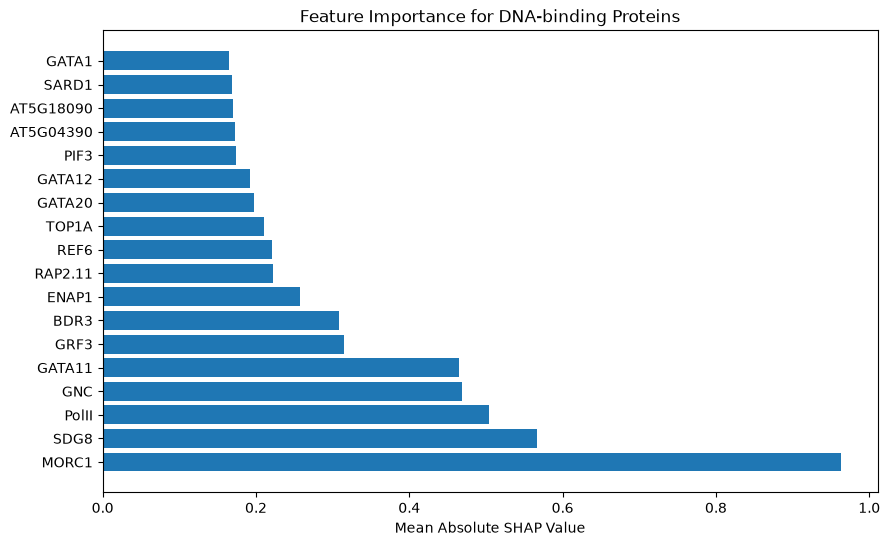

In [124]:
# bar plot for dna binding
top = 20
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.barh(dna_binding["factor type"].head(top), dna_binding["mean_abs_shap"].head(top))
plt.xlabel("Mean Absolute SHAP Value")
plt.title("Feature Importance for DNA-binding Proteins")
plt.show()

In [72]:
dna_binding.to_csv("../results/xgboost_ehnacers_500_dna_binding_c1/dna_binding_feature_importance_2.csv", index=False)

In [36]:
histone_related = importance[importance["experiment type"] == "histone related"]
histone_related.sort_values("mean_abs_shap", ascending=False)

,feature,mean_abs_shap,factor type,experiment type
2011,SRX4131142,0.586021,H3,histone related
2012,SRX4131141,0.330491,H3,histone related
255,SRX113875,0.313714,HTR5,histone related
288,SRX189361,0.185531,H3,histone related
2015,SRX4131137,0.168816,H3K4me3,histone related
...,...,...,...,...
2056,SRX4343144,0.000000,H3K9ac,histone related
2057,SRX4343146,0.000000,H3K4me3,histone related
2058,SRX4343124,0.000000,H3K9ac,histone related
2199,SRX5177413,0.000000,H3K4me3,histone related


In [37]:
histone_related.sort_values("mean_abs_shap", ascending=False).head(20)

,feature,mean_abs_shap,factor type,experiment type
2011,SRX4131142,0.586021,H3,histone related
2012,SRX4131141,0.330491,H3,histone related
255,SRX113875,0.313714,HTR5,histone related
288,SRX189361,0.185531,H3,histone related
2015,SRX4131137,0.168816,H3K4me3,histone related
194,ERX3510589,0.154796,H3K9ac|H3K14ac,histone related
267,SRX130301,0.145577,H3.3,histone related
1892,SRX3505336,0.141838,H2AZ,histone related
1940,SRX4478272,0.139810,H3K9me2,histone related
254,SRX113876,0.129674,HTR13,histone related


In [38]:
importance.to_csv("../results/xgboost_ehnacers/shap_feature_importance.csv", index=False)

In [180]:
booster = bst.get_booster()
gain_scores = booster.get_score(importance_type='gain')

In [181]:
weight_scores = booster.get_score(importance_type='weight')

In [183]:
len(weight_scores)

816

In [184]:
len(gain_scores)

816

In [192]:
feats_df_tree["factor type"]= [acc_to_factor[feature.split(".")[0]] if feature.split(".")[0] in acc_to_factor else feature.split(".")[0] for feature in feats_df_tree["feature"]]
feats_df_tree["experiment type"]= [acc_to_type[feature.split(".")[0]] if feature.split(".")[0] in acc_to_type else feature.split(".")[0] for feature in feats_df_tree["feature"]]

In [193]:
feats_df_tree.sort_values("importance", ascending=False)

,feature,importance,factor type,experiment type
616,SRX3508946,187.0,H3C,histone related
87,ERX1047449,151.0,H3,histone related
197,SRX113875,149.0,HTR5,histone related
207,SRX189361,144.0,H3,histone related
384,SRX1640071,138.0,H3,histone related
...,...,...,...,...
276,SRX1526953,0.0,H3K9me2,histone related
953,SRX7909990,0.0,H2A,histone related
954,SRX7909992,0.0,H2AX,histone related
149,ERX3510587,0.0,H3K4me3,histone related


In [144]:
feats_df_tree[feats_df_tree["experiment type"] == "DNA-binding protein"].sort_values("importance", ascending=False).head(40)

,feature,importance,factor type,experiment type
1035,SRX1161358,11591.387695,MORC1,DNA-binding protein
1036,SRX1161364,1010.283081,MORC1,DNA-binding protein
1186,SRX2613503,354.481171,PolII,DNA-binding protein
1129,SRX1748475,216.031921,ENAP1,DNA-binding protein
1196,SRX2693421,201.200363,ENAP1,DNA-binding protein
1126,SRX1748463,172.809387,ENAP1,DNA-binding protein
1034,SRX1161368,166.630875,MORC1,DNA-binding protein
1212,SRX2762745,146.955521,ELF3,DNA-binding protein
1211,SRX2762746,119.288704,ELF3,DNA-binding protein
1023,SRR1636731,114.021629,SDG8,DNA-binding protein


In [194]:
feats_df_tree.to_csv(f"../results/{out_dir}/tree_weight_feature_importance.csv", index=False)

In [127]:
mtx_mask_df = pd.read_csv("/s/chromatin/c/nobackup/Saira/BERTModel/mtx_mask.txt", sep='\t', index_col=0)

In [130]:
mtx_mask_df.head()

,2022-09-03 00:00:00,3XHMGBOX1,ABF1,ABF2,ABF3,ABF4,ABI5,ABR1,ADCP1,ADOF1,...,bZIP44,bZIP48,bZIP50,bZIP52,bZIP53,bZIP68,bZIP69,dCas9,mCG,mCHH
Sample accession,,,,,,,,,,,,,,,,,,,,,
DRX066760,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DRX066765,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DRX066790,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DRX066795,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DRX066755,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [131]:
bst.feature_importances_.shape

(2689,)

In [132]:
mtx_mask = mtx_mask_df.values

In [135]:
factor_num = np.sum(mtx_mask != 0, axis=0)
normalization_factors = np.clip(factor_num, a_min=1, a_max=None)
normalized_mtx_mask = (mtx_mask / normalization_factors)

In [137]:
factor_num.shape

(826,)

In [140]:
bst_feats = np.array(bst.feature_importances_).reshape(1, -1)
bst_feats.shape

(1, 2689)

In [142]:
avg_importance =  np.matmul(bst_feats, normalized_mtx_mask)

In [144]:
avg_importance_df = pd.DataFrame({
    "feature": mtx_mask_df.columns,
    "avg_importance": avg_importance.flatten()
}).sort_values("avg_importance", ascending=False)


In [146]:
avg_importance_df.reset_index(drop=True, inplace=True)

In [148]:
avg_importance_df.head(20)

,feature,avg_importance
0,GRF3,0.009405
1,UBQ10,0.006533
2,H3,0.003437
3,HTR5,0.003361
4,SE,0.001730
5,HTR13,0.001657
6,AGDP1,0.001584
7,GATA11,0.001182
8,NDX,0.001095
9,MYC3,0.001037
